# PRCP-1002: Handwritten Digits Recognition

## 1. Problem Statement

The objective of this project is to analyze the MNIST handwritten
digits dataset and build machine learning models to classify
handwritten digit images into one of 10 classes, representing
the digits from 0 to 9.

The project also aims to compare the performance of multiple
classification models and identify the best-performing classifier
for production.

## 2. Project Objectives

- Perform data analysis on the handwritten digit dataset.
- Understand the structure and characteristics of the image data.
- Preprocess the image data for machine learning.
- Build multiple classification models.
- Compare the performance of the different models.
- Identify the best-performing classifier for production.
- Analyze the challenges faced during the project and explain the techniques used to address them.

# Import libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()
# MNIST gives us two parts:
# Training data
#     ↓
# X_train → images
# y_train → correct digit labels

# Testing data
#     ↓
# X_test → images
# y_test → correct digit labels


# Understand the Dataset Shape

In [5]:
print("Training images shape:", X_train.shape)
#it means: 60,000 images and each image has:28 rows × 28 columns = 784 pixels(60000,28,28)
print("Training labels shape:", y_train.shape)
# means there is one label for each training image.(60000,)
print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


## 3. Dataset Structure

The MNIST dataset contains handwritten digit images belonging to 10 classes, representing the digits from 0 to 9.

Each image has a size of 28 × 28 pixels. The dataset is divided into training and testing sets.

- `X_train`: Training images
- `y_train`: Labels corresponding to training images
- `X_test`: Testing images
- `y_test`: Labels corresponding to testing images

# Basic Data Inspection

## Check pixel values

In [6]:
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())
# 0   → completely black
# 255 → completely white

Minimum pixel value: 0
Maximum pixel value: 255


## Check the labels

In [7]:
print("Unique labels:", np.unique(y_train))

Unique labels: [0 1 2 3 4 5 6 7 8 9]


## Check class distribution

In [8]:
unique, counts = np.unique(y_train, return_counts=True)

for digit, count in zip(unique, counts):
    print(f"Digit {digit}: {count} images")

Digit 0: 5923 images
Digit 1: 6742 images
Digit 2: 5958 images
Digit 3: 6131 images
Digit 4: 5842 images
Digit 5: 5421 images
Digit 6: 5918 images
Digit 7: 6265 images
Digit 8: 5851 images
Digit 9: 5949 images


## Check missing values

In [9]:
print("Missing values in training data:", np.isnan(X_train).sum())
print("Missing values in test data:", np.isnan(X_test).sum())

Missing values in training data: 0
Missing values in test data: 0


# Visualize Handwritten Digits

## Display sample images

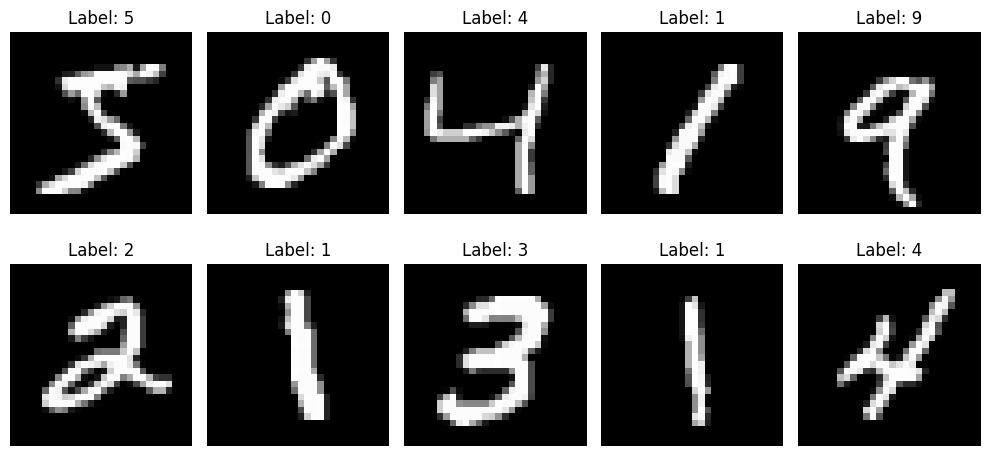

In [10]:
# Create a figure with a width of 10 inches and a height of 5 inches
plt.figure(figsize=(10, 5))

# range(10) gives us numbers from 0 to 9
# We use this because we want to display 10 images
for i in range(10):

    # Create a grid with 2 rows and 5 columns
    # i + 1 tells Python which position the current image should occupy
    plt.subplot(2, 5, i + 1)

    # Display the image from X_train
    # X_train[i] means we are taking the i-th image
    # cmap="gray" displays the image in grayscale
    plt.imshow(X_train[i], cmap="gray")

    # Display the actual digit/label above the image
    # y_train[i] contains the correct digit for that image
    plt.title(f"Label: {y_train[i]}")

    # Remove the x-axis and y-axis numbers
    # This makes the image easier to view
    plt.axis("off")

# Automatically adjust spacing between the images
plt.tight_layout()

# Display the final visualization
plt.show()

## Visualize different examples

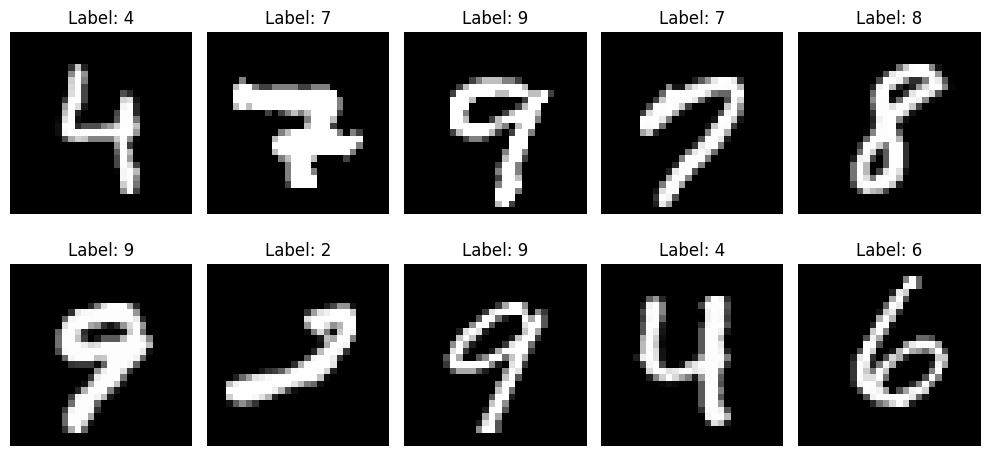

In [11]:
plt.figure(figsize=(10, 5))

random_indices = np.random.choice(len(X_train), 10, replace=False)

for i, index in enumerate(random_indices):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[index], cmap="gray")
    plt.title(f"Label: {y_train[index]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

### Observations

- The dataset contains grayscale handwritten digit images.
- Each image has a size of 28 × 28 pixels.
- The target variable contains 10 classes, representing digits from 0 to 9.
- The handwriting style and shape of the same digit can vary between images.
- The variation in handwriting makes digit classification a challenging computer vision task.

# Class Distribution

## Create a class distribution table

In [12]:
# Find each unique digit and count how many times it appears
unique, counts = np.unique(y_train, return_counts=True)

# Create a table to display the results
class_distribution = pd.DataFrame({
    "Digit": unique,
    "Number of Images": counts
})

# Display the table
class_distribution

,Digit,Number of Images
0,0,5923
1,1,6742
2,2,5958
3,3,6131
4,4,5842
5,5,5421
6,6,5918
7,7,6265
8,8,5851
9,9,5949


## Visualize class distribution

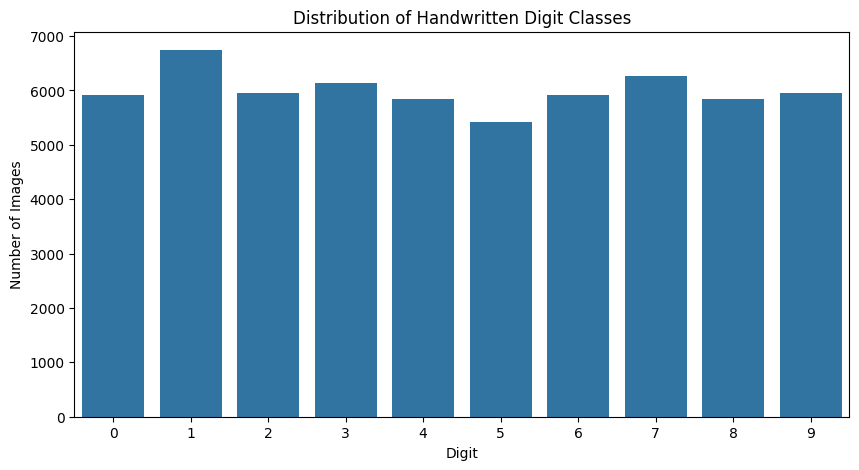

In [13]:
# Create a bar chart showing the number of images for each digit
plt.figure(figsize=(10, 5))

sns.barplot(
    data=class_distribution,
    x="Digit",
    y="Number of Images"
)

# Add a title to the chart
plt.title("Distribution of Handwritten Digit Classes")

# Label the x-axis
plt.xlabel("Digit")

# Label the y-axis
plt.ylabel("Number of Images")

# Display the chart
plt.show()

### Class Distribution Observation

The class distribution shows that all 10 digit classes are represented in the training dataset. The number of images across the classes is relatively similar, indicating that there is no severe class imbalance.

# Understand One Image at Pixel Level

## Select one image

In [14]:
# Select the first image from the training dataset
image = X_train[0]

# Display the shape of the image
print("Image shape:", image.shape)

Image shape: (28, 28)


### Look at the pixel values

In [15]:
# Display the pixel values of the first image
print(image)

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

## See the image and its pixel matrix together

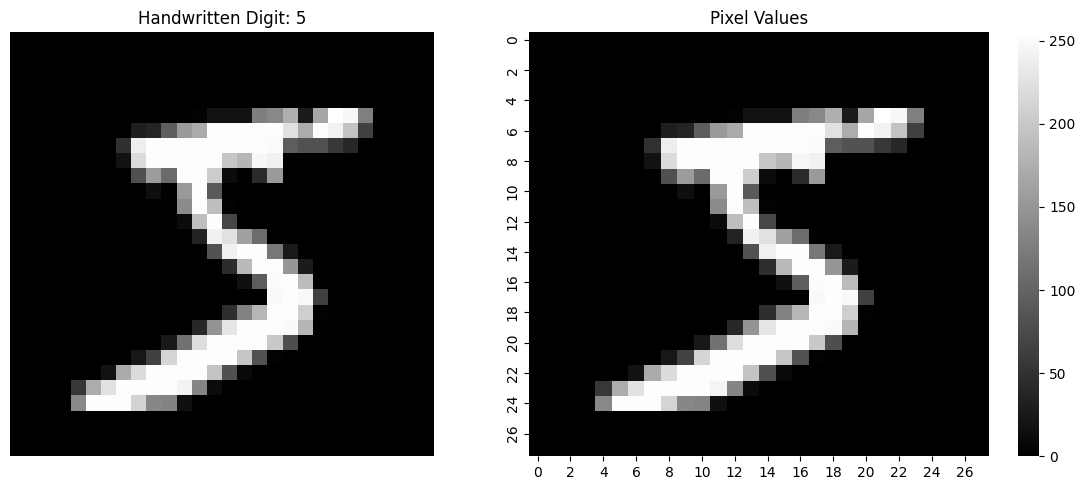

In [16]:
# Create a figure
plt.figure(figsize=(12, 5))

# Display the handwritten image
plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title(f"Handwritten Digit: {y_train[0]}")
plt.axis("off")

# Display the pixel values as a heatmap
plt.subplot(1, 2, 2)
sns.heatmap(image, cmap="gray")
plt.title("Pixel Values")

# Adjust spacing
plt.tight_layout()

# Display the figure
plt.show()

# Data Preprocessing: Normalization

## Normalize the images

In [17]:
# Convert pixel values from the range 0-255 to the range 0-1
X_train_normalized = X_train / 255.0
X_test_normalized = X_test / 255.0

# Check the new minimum and maximum values
print("Minimum pixel value:", X_train_normalized.min())
print("Maximum pixel value:", X_train_normalized.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


## Verify the image still looks correct

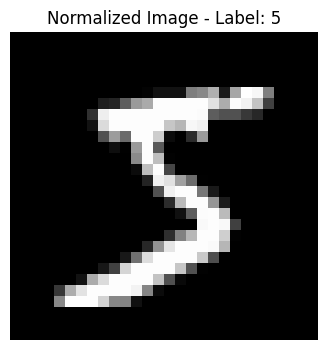

In [18]:
# Display the normalized version of the first image
plt.figure(figsize=(4, 4))

plt.imshow(X_train_normalized[0], cmap="gray")

plt.title(f"Normalized Image - Label: {y_train[0]}")
plt.axis("off")

plt.show()

# Prepare the data for Machine Learning models

## Flatten the images

In [19]:
# Convert each 28 × 28 image into a single row of 784 pixel values

X_train_flat = X_train_normalized.reshape(X_train_normalized.shape[0], -1)
# X_train_normalized.shape[0] → number of images = 60,000
# -1 → Python automatically calculates the remaining dimension = 784
# So (60000, 28, 28) becomes (60000, 784)
X_test_flat = X_test_normalized.reshape(X_test_normalized.shape[0], -1)

# Check the new shapes
print("Training data shape:", X_train_flat.shape)
print("Testing data shape:", X_test_flat.shape)

Training data shape: (60000, 784)
Testing data shape: (10000, 784)


# Logistic Regression

## Import the model

In [20]:
from sklearn.linear_model import LogisticRegression

### Create and train the model

In [29]:
# Create the Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000) #max_iter=1000 gives the model enough iterations to converge during training.

# Train the model using the training images and their labels
logistic_model.fit(X_train_flat, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


### Make predictions

In [22]:
# Predict the digits for the test images
y_pred_logistic = logistic_model.predict(X_test_flat)

# Display the first 10 predictions
print("Predicted:", y_pred_logistic[:10])
print("Actual:   ", y_test[:10])

Predicted: [7 2 1 0 4 1 4 9 6 9]
Actual:    [7 2 1 0 4 1 4 9 5 9]


### Calculate Accuracy

In [23]:
from sklearn.metrics import accuracy_score

# Calculate how many test predictions were correct
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.9258


### Confusion Matrix

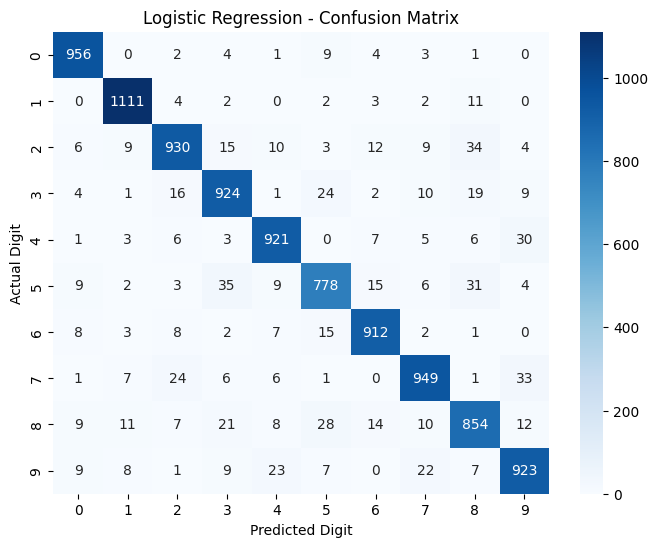

In [24]:
from sklearn.metrics import confusion_matrix

# Create the confusion matrix
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

# Display the confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.show()

# K-Nearest Neighbors (KNN)

### Import KNN

In [25]:
from sklearn.neighbors import KNeighborsClassifier

### Create and train KNN

In [26]:
# Create the KNN model
knn_model = KNeighborsClassifier(n_neighbors=3)

# Train the model
knn_model.fit(X_train_flat, y_train)

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


### Make predictions

In [27]:
# Predict the digits for the test images
y_pred_knn = knn_model.predict(X_test_flat)

# Display the first 10 predictions
print("Predicted:", y_pred_knn[:10])
print("Actual:   ", y_test[:10])

Predicted: [7 2 1 0 4 1 4 9 5 9]
Actual:    [7 2 1 0 4 1 4 9 5 9]


### Evaluate KNN Accuracy

In [28]:
from sklearn.metrics import accuracy_score

# Calculate KNN accuracy
knn_accuracy = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.9705


### KNN Confusion Matrix

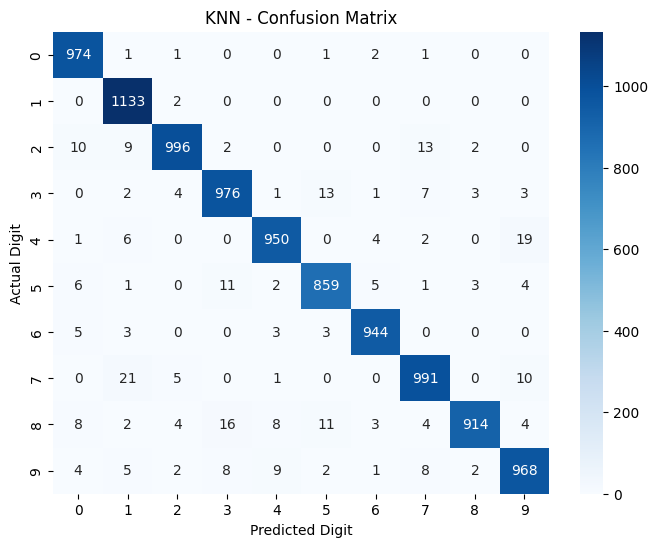

In [31]:
from sklearn.metrics import confusion_matrix

# Create the confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

# Display the confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.show()

# SVM (Support Vector Machine)

### Import SVM

In [32]:
from sklearn.svm import SVC

### Create and train the SVM model

In [33]:
# Create the SVM classifier
svm_model = SVC(kernel="rbf")

# Train the model
svm_model.fit(X_train_flat, y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


### Make predictions

In [34]:
# Predict the digits for the test images
y_pred_svm = svm_model.predict(X_test_flat)

# Display the first 10 predictions
print("Predicted:", y_pred_svm[:10])
print("Actual:   ", y_test[:10])

Predicted: [7 2 1 0 4 1 4 9 6 9]
Actual:    [7 2 1 0 4 1 4 9 5 9]


### Evaluate SVM Accuracy

In [35]:
# Calculate SVM accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.9792


### SVM Confusion Matrix

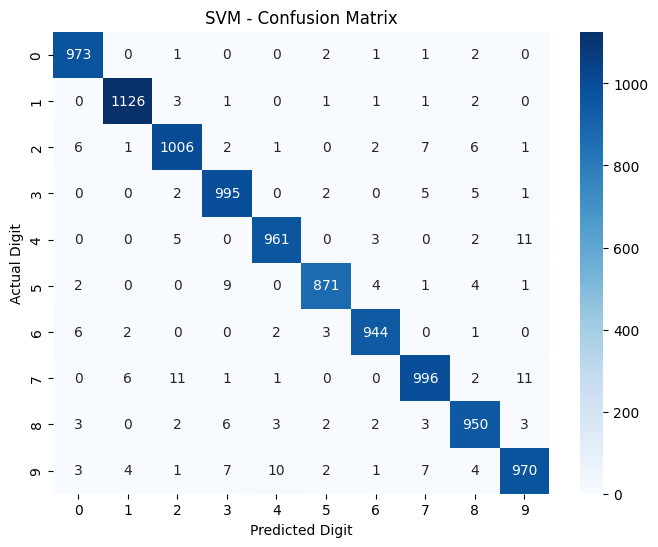

In [36]:
# Create the confusion matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

# Display the confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.show()

# Random Forest

### Import Random Forest

In [37]:
from sklearn.ensemble import RandomForestClassifier

### Create and train the model

In [38]:
# Create the Random Forest classifier
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
random_forest_model.fit(X_train_flat, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### Make predictions

In [39]:
# Predict the digits for the test images
y_pred_rf = random_forest_model.predict(X_test_flat)

# Display the first 10 predictions
print("Predicted:", y_pred_rf[:10])
print("Actual:   ", y_test[:10])

Predicted: [7 2 1 0 4 1 4 9 5 9]
Actual:    [7 2 1 0 4 1 4 9 5 9]


### Evaluate Random Forest

In [40]:
# Calculate Random Forest accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.9704


### Random Forest Confusion Matrix

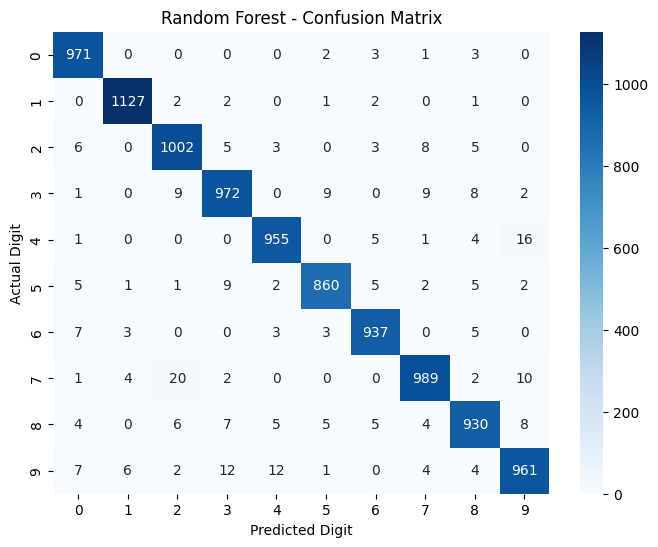

In [41]:
# Create the confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Display the confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")

plt.show()

# CNN (Convolutional Neural Network)

## prepare the CNN data

In [42]:
# Add a channel dimension to the images
X_train_cnn = X_train_normalized.reshape(-1, 28, 28, 1)
X_test_cnn = X_test_normalized.reshape(-1, 28, 28, 1)

# Check the new shapes
print("CNN training data shape:", X_train_cnn.shape)
print("CNN testing data shape:", X_test_cnn.shape)

CNN training data shape: (60000, 28, 28, 1)
CNN testing data shape: (10000, 28, 28, 1)


### Import TensorFlow/Keras layers

In [43]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

### Create the CNN 

In [44]:
cnn_model = Sequential([
    
    # Convolutional layer
    Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    
    # Reduce the image size while keeping important features
    MaxPooling2D((2, 2)),
    
    # Convert the feature maps into a single vector
    Flatten(),
    
    # Fully connected layer
    Dense(128, activation="relu"),
    
    # Output layer: 10 neurons for digits 0-9
    Dense(10, activation="softmax")
])

site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### See the CNN structure

In [45]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 5408)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         692,352 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 693,962 (2.65 MB)

 Trainable params: 693,962 (2.65 MB)

 Non-trainable params: 0 (0.00 B)

### Compile the CNN

In [46]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Train the CNN

In [47]:
history = cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 61s 66ms/step - accuracy: 0.9444 - loss: 0.1857 - val_accuracy: 0.9827 - val_loss: 0.0669
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 71s 53ms/step - accuracy: 0.9818 - loss: 0.0595 - val_accuracy: 0.9838 - val_loss: 0.0608
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 75s 44ms/step - accuracy: 0.9881 - loss: 0.0394 - val_accuracy: 0.9848 - val_loss: 0.0592
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 44ms/step - accuracy: 0.9917 - loss: 0.0268 - val_accuracy: 0.9883 - val_loss: 0.0437
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 47ms/step - accuracy: 0.9940 - loss: 0.0187 - val_accuracy: 0.9862 - val_loss: 0.0504


# Evaluate CNN

In [48]:
# Evaluate the CNN on the test dataset
cnn_loss, cnn_accuracy = cnn_model.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print("CNN Test Accuracy:", cnn_accuracy)

CNN Test Accuracy: 0.9854999780654907


# Compare Model Performance

In [49]:
# Create a table to compare all models

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "SVM",
        "Random Forest",
        "CNN"
    ],
    
    "Accuracy": [
        logistic_accuracy,
        knn_accuracy,
        svm_accuracy,
        rf_accuracy,
        cnn_accuracy
    ]
})

# Sort models from highest accuracy to lowest
model_comparison = model_comparison.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

model_comparison

,Model,Accuracy
0,CNN,0.9855
1,SVM,0.9792
2,KNN,0.9705
3,Random Forest,0.9704
4,Logistic Regression,0.9258


# Accuracy Comparison Graph

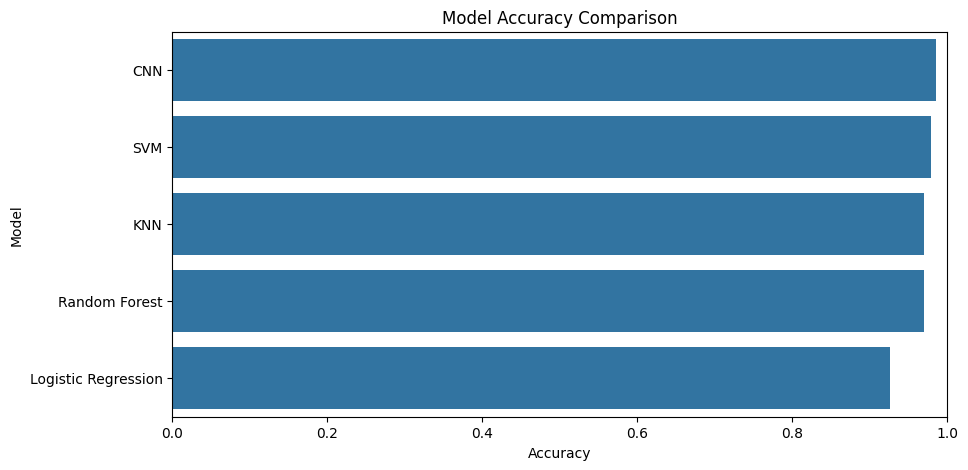

In [50]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_comparison,
    x="Accuracy",
    y="Model"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Accuracy")
plt.ylabel("Model")

plt.xlim(0, 1)

plt.show()

# Misclassification Analysis

In [51]:
# Find the model with the highest accuracy
best_model_name = model_comparison.iloc[0]["Model"]
best_accuracy = model_comparison.iloc[0]["Accuracy"]

print("Best Model:", best_model_name)
print("Best Accuracy:", best_accuracy)

Best Model: CNN
Best Accuracy: 0.9854999780654907


## Model Comparison Results

The performance of multiple classification models was evaluated on the MNIST handwritten digit dataset.

The models compared in this project are:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Support Vector Machine (SVM)
- Random Forest
- Convolutional Neural Network (CNN)

The models were evaluated based on their classification accuracy on the test dataset.

### Best Performing Model

The **Convolutional Neural Network (CNN)** achieved the highest test accuracy of **98.55%**.

This indicates that the CNN performed better than the other models evaluated in this project for handwritten digit classification.

The CNN is therefore selected as the **best-performing classifier** based on the test accuracy obtained.

# Generate CNN Predictions

In [52]:
# Generate predictions for all test images
y_pred_cnn = cnn_model.predict(X_test_cnn, verbose=0)

# Convert probability values into predicted digit labels
y_pred_cnn_labels = np.argmax(y_pred_cnn, axis=1)

# Display the first 10 predictions
print("Predicted:", y_pred_cnn_labels[:10])
print("Actual:   ", y_test[:10])

Predicted: [7 2 1 0 4 1 4 9 5 9]
Actual:    [7 2 1 0 4 1 4 9 5 9]


# Find Misclassified Images

In [53]:
# Find the positions where the prediction is incorrect
misclassified_indices = np.where(
    y_pred_cnn_labels != y_test
)[0]

# Display the total number of incorrect predictions
print("Number of misclassified images:", len(misclassified_indices))

Number of misclassified images: 145


# Display some mistakes

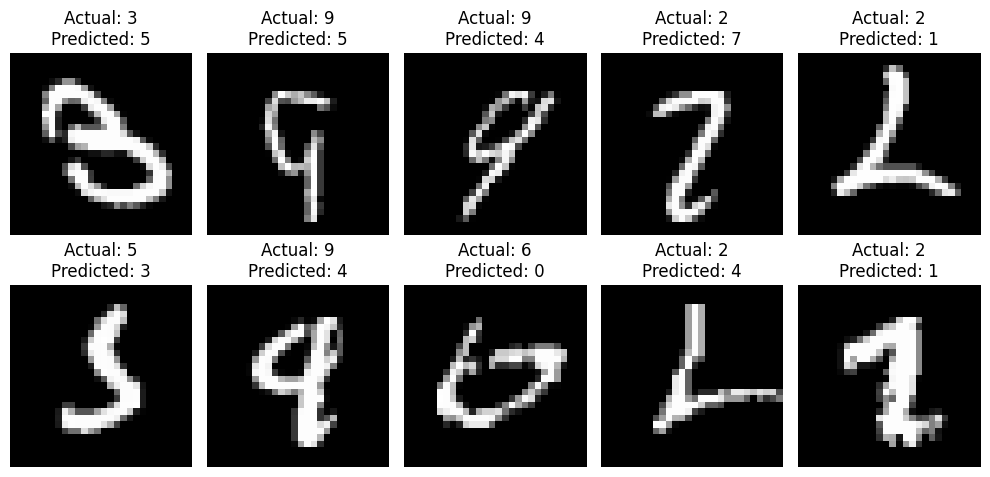

In [54]:
# Display the first 10 incorrectly classified images
plt.figure(figsize=(10, 5))

for i in range(10):

    # Get the index of a misclassified image
    index = misclassified_indices[i]

    # Create a position in the 2 × 5 grid
    plt.subplot(2, 5, i + 1)

    # Display the image
    plt.imshow(X_test[index], cmap="gray")

    # Show actual and predicted labels
    plt.title(
        f"Actual: {y_test[index]}\nPredicted: {y_pred_cnn_labels[index]}"
    )

    # Remove axes
    plt.axis("off")

plt.tight_layout()
plt.show()

## Misclassification Analysis

The CNN model achieved a test accuracy of **98.55%**, which means that most of the handwritten digit images were classified correctly.

The misclassified images were analyzed by comparing their actual labels with the predicted labels. Some handwritten digits were incorrectly classified because different digits can have similar shapes or writing patterns.

For example, handwritten digits may contain variations in:

- Shape and writing style
- Stroke thickness
- Slant and orientation
- Similar visual patterns between different digits

The misclassified-image visualization helps identify the types of handwritten digits that are more difficult for the CNN to distinguish.

# Classification Report

In [55]:
from sklearn.metrics import classification_report

# Generate precision, recall and F1-score for each digit
cnn_report = classification_report(
    y_test,
    y_pred_cnn_labels
)

print(cnn_report)

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.98      1.00      0.99      1135
           2       0.99      0.97      0.98      1032
           3       0.98      0.99      0.99      1010
           4       0.97      1.00      0.98       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.98      0.99      1028
           8       0.99      0.98      0.99       974
           9       0.99      0.97      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



# Challenges Faced

## Challenges Faced and Techniques Used

During the project, the following challenges were observed:

### 1. Variation in Handwriting
Different people write the same digit in different styles. This creates variations in shape, size, stroke thickness, and orientation.

**Technique used:** The CNN was used to learn important visual patterns from the handwritten images.

### 2. Similar-Looking Digits
Some handwritten digits can have similar shapes, which can lead to incorrect predictions.

**Technique used:** Misclassified images were analyzed to understand the types of errors made by the model.

### 3. Different Pixel Values
The original MNIST images contain pixel values ranging from 0 to 255.

**Technique used:** Pixel values were normalized to a range of 0 to 1 by dividing them by 255.

### 4. Choosing the Best Classifier
Different classification algorithms can perform differently on image data.

**Technique used:** Logistic Regression, KNN, SVM, Random Forest, and CNN were trained and their performance was compared.